# 03. 분류 확률 재기 — calibration과 conformal prediction

분류 모델의 확률이 "80%"라고 말하면, 그렇게 말한 행 가운데 80%쯤이 실제로 맞아야 믿고 쓸 수 있습니다. 이것을 calibration이라고 합니다. 정확도나 ROC AUC는 확률의 순서만 보므로 이것을 재지 못합니다. 이 노트북은 calibration을 재는 ECE와, 확률이 틀려도 "정답을 90% 담는 후보 집합"을 만들어 주는 conformal prediction을 작은 예로 따라갑니다. 구현은 `minipfn/benchmarks/uncertainty.py`입니다(issue #45).

다루는 흐름:

1. 손으로 보는 ECE
2. 온도로 확신을 바꿔 보기 — reliability diagram
3. conformal prediction — 정답을 90% 담는 집합
4. 온도가 달라도 coverage는 지킨다
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_evaluation/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 2절부터 Hub에서 v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받습니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import make_classification

from minipfn import TabPFNv2Classifier, set_seed
from minipfn.benchmarks import uncertainty as unc

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 손으로 보는 ECE

모델이 행 10개에 낸 예측입니다. "확신도"는 가장 큰 클래스 확률(top-label confidence)이고, "맞음"은 그 클래스가 정답인지입니다.

ECE(expected calibration error)는 확신도를 구간으로 묶고, 구간마다 "평균 확신도"와 "실제 정답률"의 차이를 그 구간의 행 수로 가중 평균합니다. 저장소는 같은 폭의 구간 15개를 씁니다. 여기서는 손으로 따라가기 쉽게 구간 2개(0.5~0.75, 0.75~1)로 나눕니다.

In [3]:
hand = pd.DataFrame(
    {
        "확신도": [0.95, 0.90, 0.92, 0.88, 0.97, 0.60, 0.55, 0.65, 0.70, 0.58],
        "맞음": [1, 1, 0, 1, 1, 1, 0, 0, 1, 0],
    }
)
hand["구간"] = np.where(hand["확신도"] >= 0.75, "0.75~1", "0.5~0.75")
per_bin = hand.groupby("구간").agg(
    행=("맞음", "size"), 평균_확신도=("확신도", "mean"), 정답률=("맞음", "mean")
)
per_bin["차이"] = (per_bin["정답률"] - per_bin["평균_확신도"]).abs()
display(per_bin.round(3))
by_hand = (per_bin["행"] * per_bin["차이"]).sum() / len(hand)
print(f"ECE (구간 2개, 손으로): {by_hand:.3f}")

# 저장소 함수는 (행 × 클래스) 확률과 정답 번호를 받는다. 이진 분류로 바꿔 넣는다.
# 같은 폭의 구간 4개(0.25씩)면 이 10행은 0.5~0.75와 0.75~1 두 구간에만 들어간다
proba = np.column_stack([hand["확신도"], 1 - hand["확신도"]])  # 0번 클래스를 예측
labels = np.where(hand["맞음"] == 1, 0, 1)  # 맞으면 정답이 0번
print(f"ECE (unc.ece, 구간 4개): {unc.ece(proba, labels, n_bins=4):.3f}")

,행,평균_확신도,정답률,차이
구간,,,,
0.5~0.75,5,0.616,0.4,0.216
0.75~1,5,0.924,0.8,0.124


ECE (구간 2개, 손으로): 0.170
ECE (unc.ece, 구간 4개): 0.170


확신도가 높은 구간은 평균 0.92라고 말했고 실제로 0.8을 맞혔습니다. 낮은 구간은 0.62라고 말했고 0.4를 맞혔습니다. 두 구간 모두 말한 것보다 덜 맞으니 이 모델은 지나치게 확신합니다. 두 차이를 행 수로 평균한 0.17이 ECE입니다. 0이면 말한 만큼 맞힌다는 뜻입니다.

## 2. 온도로 확신을 바꿔 보기 — reliability diagram

TabPFN v2 하나를 softmax 온도만 바꿔 세 가지로 씁니다. 온도는 [topics_inference/02](../topics_inference/02_greedy_ensemble_selection.ipynb) 2절에서 본 것처럼 확률을 날카롭게(1보다 작음) 하거나 무디게(1보다 큼) 합니다. 기본값은 0.9입니다. 데이터는 클래스 4개, feature 10개짜리를 만들고, 정답의 5%를 무작위로 바꿔 모델이 다 맞힐 수 없게 했습니다. 학습 행은 300개, test 행은 1,200개입니다.

In [4]:
x, y = make_classification(
    1500,
    n_features=10,
    n_informative=5,
    n_classes=4,
    n_clusters_per_class=1,
    class_sep=0.8,
    flip_y=0.05,
    random_state=0,
)
x_tr, y_tr, x_te, y_te = x[:300], y[:300], x[300:], y[300:]

model = TabPFNv2Classifier().model  # aiden-jeon/minipfn-tabpfn-v2-classifier
temperatures = {"sharp (T=0.25)": 0.25, "default (T=0.9)": 0.9, "soft (T=2.0)": 2.0}
probas = {}
metric_rows = {}
for name, t in temperatures.items():
    clf = TabPFNv2Classifier(model, n_estimators=4, softmax_temperature=t).fit(x_tr, y_tr)
    probas[name] = clf.predict_proba(x_te)
    metrics = unc.classification_metrics(probas[name], y_te, clf.classes_)
    metric_rows[name] = {
        "정확도": (probas[name].argmax(1) == y_te).mean(),
        "평균 확신도": probas[name].max(1).mean(),
        "ECE": metrics["ece"],
        "log loss": metrics["log_loss"],
        "Brier": metrics["brier"],
    }
display(pd.DataFrame(metric_rows).T.round(3))

,정확도,평균 확신도,ECE,log loss,Brier
sharp (T=0.25),0.737,0.914,0.177,1.500,0.430
default (T=0.9),0.737,0.761,0.038,0.726,0.369
soft (T=2.0),0.737,0.562,0.176,0.802,0.419


정확도는 세 온도 모두 0.737로 같습니다. 이 데이터에서는 온도를 바꿔도 행마다 가장 큰 클래스가 그대로였습니다. 바뀌는 것은 확신도입니다. 평균 확신도가 sharp 0.914, 기본 0.761, soft 0.562이고, 실제 정답률 0.737에 가장 가까운 기본 온도의 ECE가 0.038로 가장 작습니다. sharp는 맞히는 것보다 훨씬 자신 있게, soft는 훨씬 자신 없게 말해서 ECE가 둘 다 0.18쯤으로 나쁩니다. log loss는 sharp가 특히 나쁩니다(1.500). 자신 있게 틀린 행의 벌점이 크기 때문입니다.

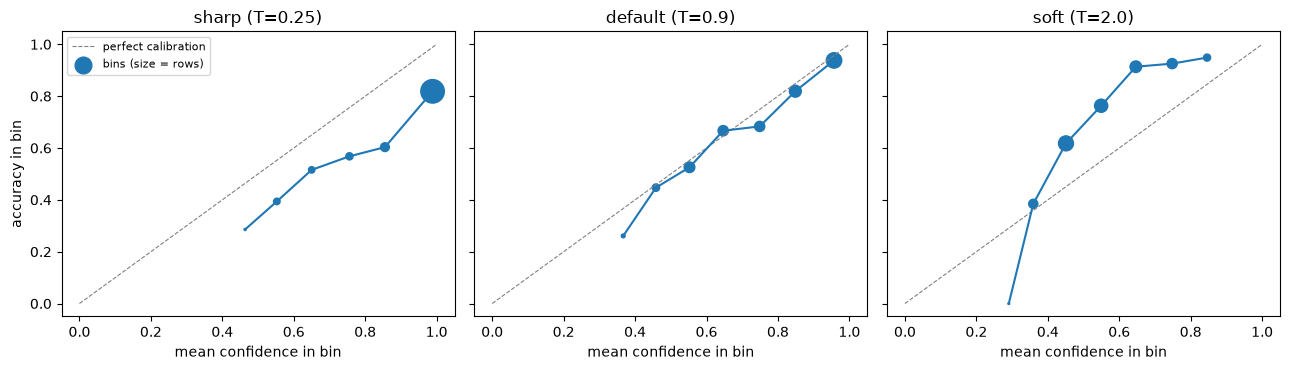

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
edges = np.linspace(0, 1, 11)
for ax, (name, proba) in zip(axes, probas.items(), strict=True):
    confidence = proba.max(1)
    correct = proba.argmax(1) == y_te
    which = np.clip(np.digitize(confidence, edges) - 1, 0, 9)
    centers, accuracy, counts = [], [], []
    for b in range(10):
        rows = which == b
        if rows.sum() >= 5:  # 행이 너무 적은 구간은 그리지 않는다
            centers.append(confidence[rows].mean())
            accuracy.append(correct[rows].mean())
            counts.append(rows.sum())
    ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=0.8, label="perfect calibration")
    ax.scatter(centers, accuracy, s=np.array(counts) / 3, label="bins (size = rows)")
    ax.plot(centers, accuracy)
    ax.set_title(name)
    ax.set_xlabel("mean confidence in bin")
axes[0].set_ylabel("accuracy in bin")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

점선 위에 있으면 말한 만큼 맞힌 것입니다. sharp는 모든 구간이 점선 아래(말한 것보다 덜 맞힘)이고, 특히 행이 가장 많은 마지막 구간에서 0.99라고 말하고 0.82를 맞혔습니다. soft는 점선 위(말한 것보다 더 맞힘)입니다. 기본 온도는 점선을 거의 따라갑니다.

## 3. conformal prediction — 정답을 90% 담는 집합

calibration이 맞지 않는 확률이라도, 클래스 하나 대신 클래스 **집합**을 내면 "이 집합에 정답이 있을 확률이 적어도 90%"를 보장할 수 있습니다. split conformal prediction은 모델을 다시 학습하지 않고, 정답을 아는 행(calibration 행)만 조금 더 있으면 됩니다. LAC 점수(Sadinle et al. 2019)로 단계를 따라갑니다. 목표는 $\alpha = 0.1$, 곧 90%입니다.

1. calibration 행마다 점수 $s = 1 - p_{\text{정답}}$을 계산합니다. 정답에 준 확률이 작을수록 "이상한" 행입니다.
2. 점수를 작은 순서로 세워 $\lceil (n+1)(1-\alpha) \rceil$번째 값을 기준 $q$로 둡니다.
3. 새 행에서는 $1 - p_k \le q$, 곧 $p_k \ge 1 - q$인 클래스 $k$를 모두 집합에 넣습니다.

test 행 1,200개를 반으로 나눠 앞 600개를 calibration에, 뒤 600개를 평가에 씁니다. 기본 온도의 확률을 씁니다.

In [6]:
proba = probas["default (T=0.9)"]
cal, ev = np.arange(600), np.arange(600, 1200)

cal_scores = 1 - proba[cal, y_te[cal]]  # 1단계
q = unc.conformal_threshold(cal_scores, alpha=0.1)  # 2단계: ⌈(n+1)(1-α)⌉번째 값
print(f"기준 q = {q:.3f}: 확률이 {1 - q:.3f} 이상인 클래스를 집합에 넣는다")

sets = proba[ev] >= 1 - q  # 3단계: (행, 클래스) 집합에 넣는지
examples = pd.DataFrame(proba[ev][:6].round(3), columns=[f"p{k}" for k in range(4)])
examples["집합"] = [str(np.flatnonzero(s).tolist()) for s in sets[:6]]
examples["정답"] = y_te[ev][:6]
display(examples)

covered = sets[np.arange(len(ev)), y_te[ev]]
print(f"평가 행 coverage: {covered.mean():.3f}, 평균 집합 크기: {sets.sum(1).mean():.2f}")
print("집합 크기별 행 수:", pd.Series(sets.sum(1)).value_counts().sort_index().to_dict())

기준 q = 0.825: 확률이 0.175 이상인 클래스를 집합에 넣는다


,p0,p1,p2,p3,집합,정답
0,0.393,0.062,0.395,0.150,"[0, 2]",0
1,0.052,0.034,0.009,0.904,[3],3
2,0.828,0.103,0.056,0.013,[0],0
3,0.092,0.006,0.089,0.813,[3],3
4,0.704,0.004,0.285,0.007,"[0, 2]",2
5,0.572,0.003,0.401,0.023,"[0, 2]",2


평가 행 coverage: 0.873, 평균 집합 크기: 1.52
집합 크기별 행 수: {1: 320, 2: 247, 3: 32, 4: 1}


기준이 $q = 0.825$이므로 확률이 0.175 이상인 클래스가 모두 집합에 들어갑니다. 1번 행처럼 모델이 확신하면(0.904) 집합에 클래스가 하나이고, 0번 행처럼 두 클래스 사이에서 헷갈리면(0.393, 0.395) 둘 다 넣습니다. 4·5번 행은 확률이 가장 큰 클래스(0)가 틀렸지만 집합에 정답(2)이 들어 있습니다.

평가 행 600개의 coverage는 0.873입니다. 90% 보장은 calibration·평가 행을 나누는 무작위성에 대한 평균이라, 한 번 나눈 결과는 90% 위아래로 흔들립니다. 그래서 저장소는 나누기를 20번 반복해 평균합니다(4절).

## 4. 온도가 달라도 coverage는 지킨다

2절의 세 온도에 같은 절차를 씁니다. 저장소의 `conformal`은 calibration·평가 절반을 무작위로 20번 다시 나눠 평균하고, coverage와 집합 크기 말고 두 가지를 더 냅니다.

- **SSCS**(size-stratified coverage): 집합 크기 묶음(0~1개, 2~3개, …)마다의 coverage 가운데 가장 낮은 값. 집합이 작은(모델이 확신한) 행에서도 90%를 지키는지 봅니다.
- **클래스 coverage gap**: 클래스마다 coverage가 90%에서 얼마나 떨어져 있는지의 평균. 어떤 클래스는 늘 담고 어떤 클래스는 자주 놓치는지 봅니다.

점수는 LAC와 APS(Romano et al. 2020, 정답보다 확률이 큰 클래스들의 확률 합)를 둘 다 봅니다.

In [7]:
conformal_rows = {}
for name, p in probas.items():
    for kind in ["lac", "aps"]:
        result = unc.conformal(p, y_te, alpha=0.1, kind=kind)
        conformal_rows[(name, kind.upper())] = result
conformal_table = pd.DataFrame(conformal_rows).T
conformal_table.columns = ["coverage", "평균 집합 크기", "SSCS", "클래스 coverage gap"]
display(conformal_table.round(3))

coverage  평균 집합 크기   SSCS  클래스 coverage gap
sharp (T=0.25)  LAC     0.898     1.608  0.872             0.042
                APS     0.901     1.631  0.877             0.040
default (T=0.9) LAC     0.898     1.598  0.876             0.039
                APS     0.904     1.786  0.861             0.037
soft (T=2.0)    LAC     0.898     1.607  0.880             0.039
                APS     0.902     1.887  0.836             0.036

coverage는 여섯 경우 모두 0.898~0.904로 90%에 맞습니다. 2절에서 ECE가 0.18이던 sharp와 soft도 마찬가지입니다. conformal은 확률이 말하는 값을 그대로 믿지 않고, calibration 행에서 정답의 점수가 실제로 어디쯤 나오는지를 보고 기준을 정하기 때문입니다.

집합 크기는 점수에 따라 다르게 움직입니다. LAC는 세 온도에서 1.60 안팎으로 거의 같습니다. LAC 집합은 "확률이 기준 이상인 클래스"인데, 온도가 확률을 바꾸면 기준도 따라 움직여서 집합이 거의 그대로 남습니다. APS는 정답보다 큰 확률들의 합을 쓰므로 확률이 무딜수록 집합이 커집니다(1.63 → 1.79 → 1.89). SSCS는 0.84~0.88로 90%보다 조금 낮습니다. 전체 coverage가 맞아도 집합 크기 묶음 가운데 어딘가에서는 정답을 조금 더 자주 놓친다는 뜻입니다.

## 5. 정리

| 지표 | 무엇을 보나 | 좋은 값 | `uncertainty.py` |
|---|---|---|---|
| ECE | 확신도와 실제 정답률의 차이 (구간 15개) | 0 | `ece` |
| log loss, Brier | 확률 전체의 점수 (proper scoring rule) | 작을수록 | `classification_metrics` |
| conformal coverage | 집합이 정답을 담는 비율 | 1 − α (0.9) | `conformal` |
| 평균 집합 크기 | 같은 coverage에서 얼마나 좁게 말하나 | 작을수록 | `conformal` |
| SSCS | 집합 크기 묶음마다의 coverage 최솟값 | 1 − α에 가깝게 | `size_stratified_coverage` |
| 클래스 coverage gap | 클래스마다 coverage가 1 − α에서 떨어진 정도 | 0 | `conformal` |

- 온도는 정확도를 거의 바꾸지 않고 calibration만 바꿉니다(2절). [topics_inference/02](../topics_inference/02_greedy_ensemble_selection.ipynb)에서 greedy 선택이 낮은 온도를 골라 손해를 본 것이 이 노트북의 sharp와 같은 현상입니다.
- conformal prediction은 확률이 잘 맞지 않아도 coverage를 지킵니다(4절). 확률의 질이 집합 크기로 얼마나 드러나는지는 점수마다 다릅니다(APS는 무딘 확률에서 집합이 커지고, LAC는 거의 그대로입니다).
- 평가 명령: `scripts/tabpfn_v2/eval.py --uncertainty`(AMLB 분류 fold마다 이 지표를 남깁니다).